In [ ]:
import rasterio as r
import numpy as np
import matplotlib.pyplot as plt
from rasterio.plot import show, show_hist
from glob import glob
import cv2
import seaborn as sns
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import random
import os
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor


In [5]:
forest_data = glob("D:/coding files/sentienl2/EuroSAT_MS/Forest/*.tif")
annualCrop_data = glob("D:/coding files/sentienl2/EuroSAT_MS/AnnualCrop/*.tif")
HerbaceousVegetation_data = glob("D:/coding files/sentienl2/EuroSAT_MS/HerbaceousVegetation/*.tif")
Highway_data = glob("D:/coding files/sentienl2/EuroSAT_MS/Highway/*.tif")
Industrial_data = glob("D:/coding files/sentienl2/EuroSAT_MS/Industrial/*.tif")
Pasture_data = glob("D:/coding files/sentienl2/EuroSAT_MS/Pasture/*.tif")
PermanentCrop_data = glob("D:/coding files/sentienl2/EuroSAT_MS/PermanentCrop/*.tif")
Residential_data = glob("D:/coding files/sentienl2/EuroSAT_MS/Residential/*.tif")
River_data = glob("D:/coding files/sentienl2/EuroSAT_MS/River/*.tif")
SeaLake_data = glob("D:/coding files/sentienl2/EuroSAT_MS/SeaLake/*.tif")


In [37]:
labels = [
    "Highway", "Industrial", "Pasture", "PermanentCrop",
    "Residential", "River", "SeaLake"
]
values = [
    len(Highway_data), len(Industrial_data), len(Pasture_data),
    len(PermanentCrop_data), len(Residential_data),
    len(River_data), len(SeaLake_data)
]
colors = [
    "grey",       # Highway
    "lightgrey",  # Industrial
    "#4A943E",    # Pasture
    "#808000",    # PermanentCrop
    "brown",      # Residential
    "#97D7FF",    # River
    "darkblue"    # SeaLake
]

figure = go.Figure(
    go.Pie(labels=labels, values=values, marker=dict(colors=colors))
)
figure.update_layout(
    title_text="Distribution of EuroSAT_MS Dataset Classes",
    title_font=dict(size=24, family="Arial", color="white"),
    title_x=0.5,
    paper_bgcolor="black",  # outside the plot area
    plot_bgcolor="black",   # plot area
    font=dict(color="white"),
    legend=dict(
        title="Classes:",
        font=dict(size=15, family="Arial", color="white"),
        orientation="h",
        xanchor="center",
        x=0.5,
        y=-0.1
    )
)
figure.show()

In [70]:
forset_img = r.open(forest_data[0])
river_img = r.open(River_data[0])
sea_img = r.open(SeaLake_data[2])
residential_img = r.open(Residential_data[0])
highway_img = r.open(Highway_data[0])
idustrial_img = r.open(Industrial_data[0])
permanentCrop_img = r.open(PermanentCrop_data[0])
pasture_img = r.open(Pasture_data[0])
herbaceousVegetation_img = r.open(HerbaceousVegetation_data[0])
annualCrop_img = r.open(annualCrop_data[0])
images = [
    (forset_img, "Forest"),
    (river_img, "River"),
    (sea_img, "SeaLake"),
    (residential_img, "Residential"),
    (highway_img, "Highway"),
    (idustrial_img, "Industrial"),
    (permanentCrop_img, "PermanentCrop"),
    (pasture_img, "Pasture"),
    (herbaceousVegetation_img, "HerbaceousVegetation"),
    (annualCrop_img, "AnnualCrop")
]



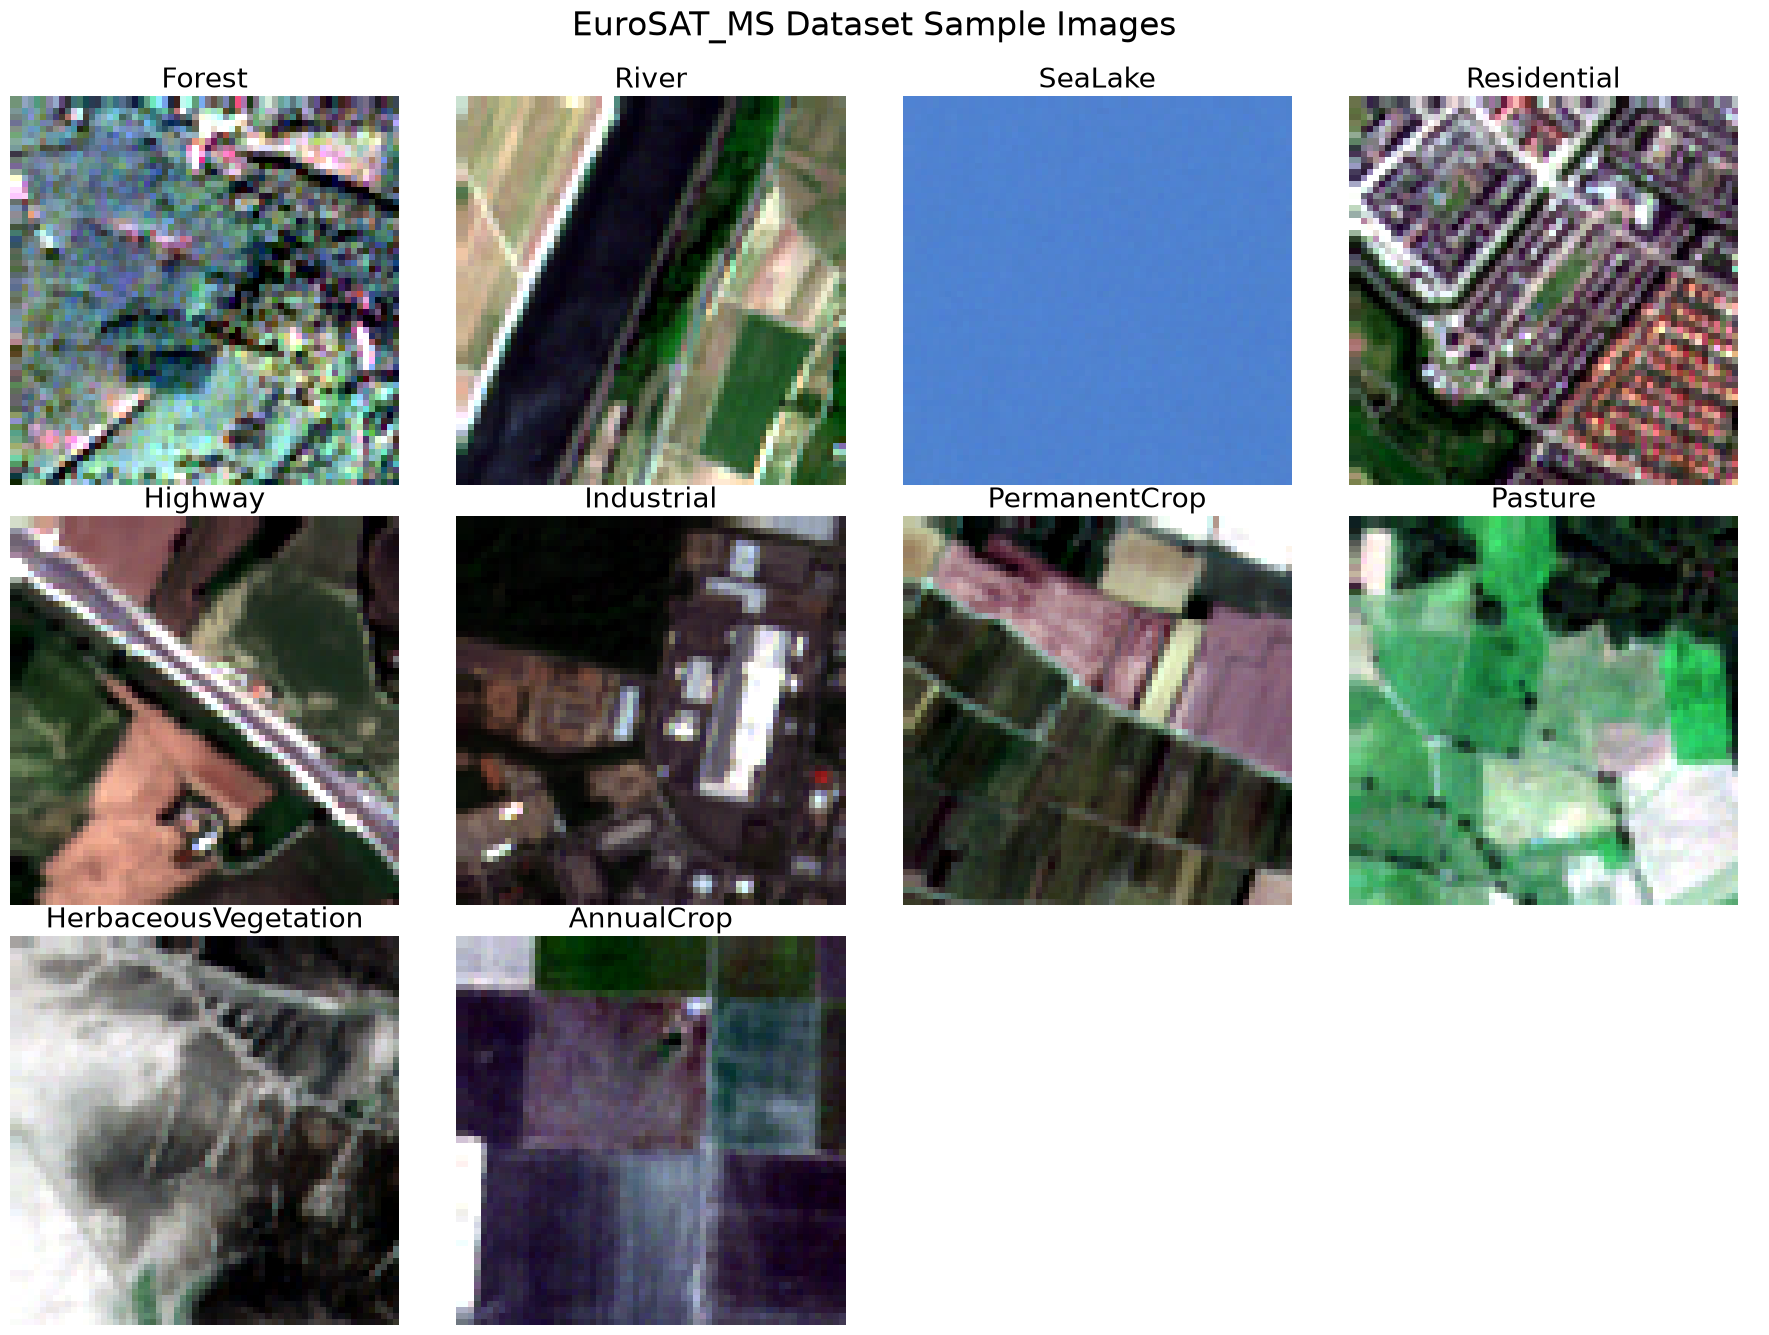

In [71]:
figure, axes = plt.subplots(3, 4, figsize=(18, 14))
figure.suptitle("EuroSAT_MS Dataset Sample Images", fontsize=24, color="black", y=0.95)
for ax, (src, title) in zip(axes.flat, images):
    if title == "SeaLake":
        rgb = np.moveaxis(sea_img.read([4, 3, 2]), 0, -1).astype(np.float32)
        rgb = np.clip(rgb / 1000.0, 0, 1)
        
    else:
        rgb = np.moveaxis(src.read([4, 3, 2]), 0, -1).astype(np.float32)

        low = np.percentile(rgb, 2, axis=(0, 1), keepdims=True)
        high = np.percentile(rgb, 98, axis=(0, 1), keepdims=True)
        rgb = np.clip((rgb - low) / np.maximum(high - low, 1e-6), 0, 1)

    ax.imshow(rgb)
    ax.set_title(title, fontsize=20)
    ax.axis("off")
    
for ax in axes.flat[len(images):]:
    ax.axis("off")
figure.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [76]:
rows = []

for src, title in images:
    data = src.read()  # read all bands once

    rows.append({
        "Class": title,
        "Dimensions": f"{src.width} × {src.height}",
        "Data type": src.dtypes[0],
        "Minimum": data.min(),
        "Maximum": data.max(),
        "Number of bands": src.count
    })

df = pd.DataFrame(rows).set_index("Class")
display(df)

,Dimensions,Data type,Minimum,Maximum,Number of bands
Class,,,,,
Forest,64 × 64,uint16,7,5087,13
River,64 × 64,uint16,8,4392,13
SeaLake,64 × 64,uint16,4,1222,13
Residential,64 × 64,uint16,6,4826,13
Highway,64 × 64,uint16,12,5414,13
Industrial,64 × 64,uint16,9,7494,13
PermanentCrop,64 × 64,uint16,8,4748,13
Pasture,64 × 64,uint16,9,5247,13
HerbaceousVegetation,64 × 64,uint16,14,3851,13


In [79]:
class_files = {
    "Forest": forest_data,
    "AnnualCrop": annualCrop_data,
    "HerbaceousVegetation": HerbaceousVegetation_data,
    "Highway": Highway_data,
    "Industrial": Industrial_data,
    "Pasture": Pasture_data,
    "PermanentCrop": PermanentCrop_data,
    "Residential": Residential_data,
    "River": River_data,
    "SeaLake": SeaLake_data,
}

rows = []

for class_name, files in class_files.items():
 
    sample = files
    band_means = []

    for path in sample:
        with r.open(path) as src:
            # Calculate the mean pixel value for each band in this image.
            image_mean = src.read().mean(axis=(1, 2))
            band_means.append(image_mean)

    # Average each band's mean across all images in this class.
    class_mean = np.mean(band_means, axis=0)

    for band_index, mean_value in enumerate(class_mean, start=1):
        rows.append({
            "Class": class_name,
            "Band": f"Band {band_index}",
            "Mean value": mean_value
        })

df_signature = pd.DataFrame(rows)

fig = px.line(
    df_signature,
    x="Band",
    y="Mean value",
    color="Class",
    markers=True,
    title="Mean Spectral Signature by Land-Cover Class",
    category_orders={
        "Band": [f"Band {i}" for i in range(1, 14)]
    }
)

fig.update_layout(
    xaxis_title="Spectral band",
    yaxis_title="Mean pixel value",
    hovermode="x unified"
)

fig.show()

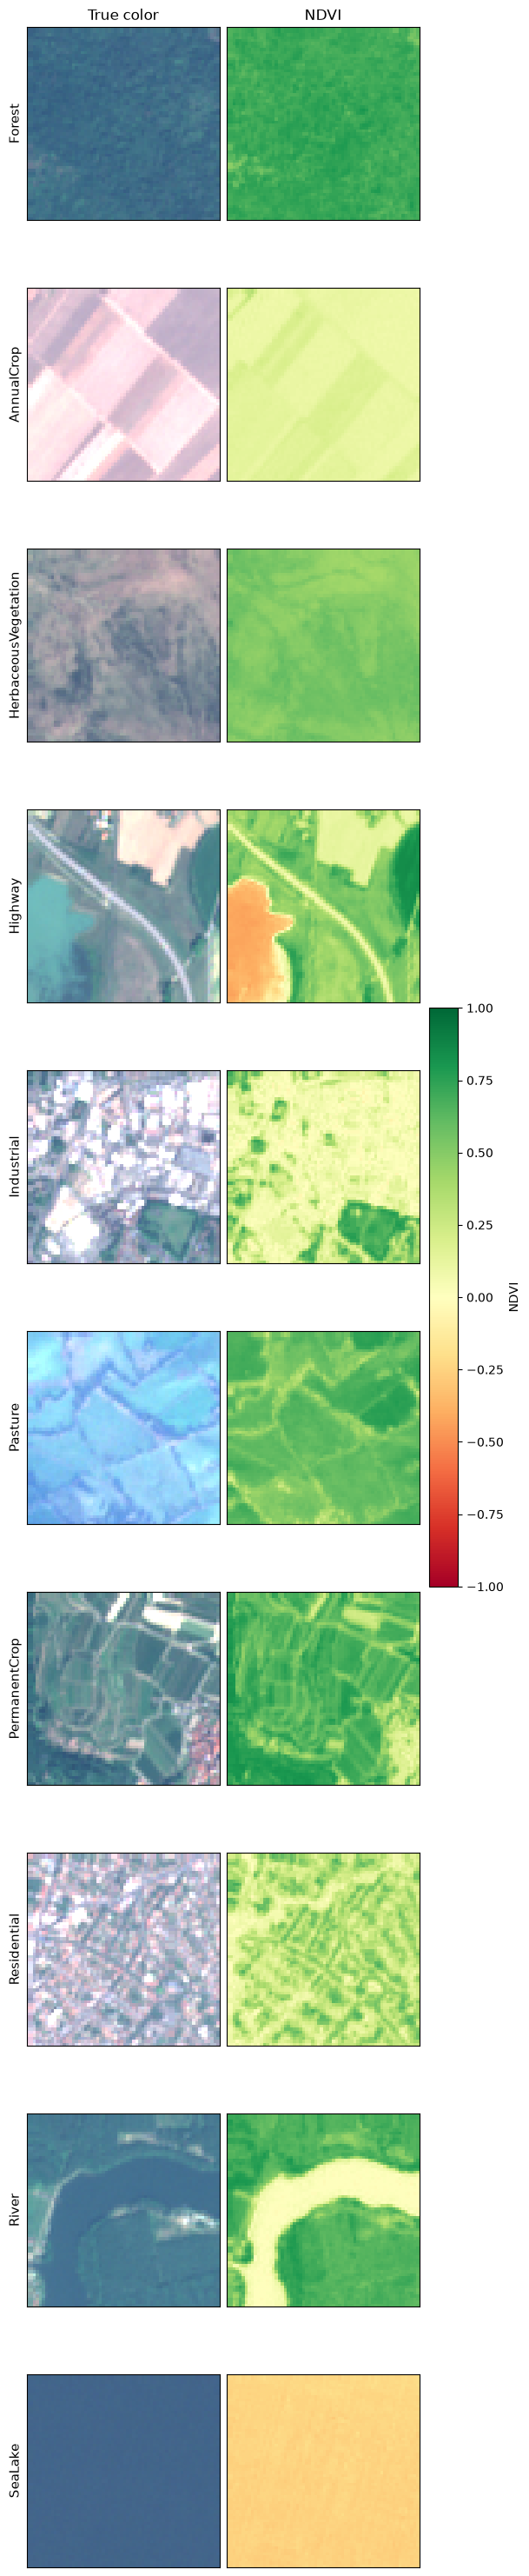

In [86]:
import random

# 0-based indices (file order: B01..B12, then B8A last)
BLUE, GREEN, RED, NIR = 1, 2, 3, 7

def stretch_rgb(rgb, vmax=1500):
    """Fixed scale: same brightness mapping for every image."""
    return np.clip(rgb / vmax, 0, 1)

def ndvi(bands):
    nir = bands[NIR].astype("float32")   # cast first: raw values are uint16
    red = bands[RED].astype("float32")
    return (nir - red) / (nir + red + 1e-6)   # 1e-6 avoids division by zero

random.seed(42)
n_per_class = 1   # raise to 2 or 3 to see more samples per class

fig, axes = plt.subplots(
    len(class_files), 2 * n_per_class,
    figsize=(3 * 2 * n_per_class, 3 * len(class_files)),
    squeeze=False, layout="constrained",
)

for row, (class_name, files) in enumerate(class_files.items()):
    for k, path in enumerate(random.sample(files, n_per_class)):
        with r.open(path) as src:
            bands = src.read()                      # shape: (13, 64, 64)

        # true color: stack R, G, B -> (H, W, 3) for imshow
        rgb = np.stack([bands[RED], bands[GREEN], bands[BLUE]], axis=-1).astype("float32")

        ax_rgb, ax_ndvi = axes[row, 2 * k], axes[row, 2 * k + 1]
        ax_rgb.imshow(stretch_rgb(rgb))
        im = ax_ndvi.imshow(ndvi(bands), cmap="RdYlGn", vmin=-1, vmax=1)

        for ax in (ax_rgb, ax_ndvi):
            ax.set_xticks([]); ax.set_yticks([])
        if k == 0:
            ax_rgb.set_ylabel(class_name, fontsize=11)
        if row == 0:
            ax_rgb.set_title("True color")
            ax_ndvi.set_title("NDVI")

fig.colorbar(im, ax=axes[:, -1], shrink=0.5, label="NDVI")
plt.show()

In [90]:
import os
import numpy as np
import pandas as pd
import plotly.express as px
import rasterio as r
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

CACHE = "index_stats.csv"

def process(item):
    class_name, path = item
    try:
        with r.open(path) as src:
            # rasterio bands are 1-based: 3 = Green, 4 = Red, 8 = NIR
            green, red, nir = src.read([3, 4, 8]).astype("float32")
    except Exception as e:                      # skip a corrupted file instead of crashing
        print("skip", path, e)
        return None
    ndvi = (nir - red) / (nir + red + 1e-6)
    ndwi = (green - nir) / (green + nir + 1e-6)
    return {"Class": class_name, "NDVI": float(ndvi.mean()), "NDWI": float(ndwi.mean())}

if os.path.exists(CACHE):
    df_idx = pd.read_csv(CACHE)
else:
    items = [(c, p) for c, files in class_files.items() for p in files]
    with ThreadPoolExecutor(max_workers=8) as ex:
        results = list(tqdm(ex.map(process, items), total=len(items)))
    df_idx = pd.DataFrame([x for x in results if x is not None])
    df_idx.to_csv(CACHE, index=False)

print(len(df_idx), "images used")          # should be about 27000
print(df_idx["Class"].value_counts())      # also gives you the class balance

fig = px.histogram(
    df_idx, x="NDVI", color="Class",
    nbins=80, barmode="overlay", opacity=0.55,
    histnorm="probability density",
    title="NDVI distribution by class (all images, mean NDVI per image)",
)
fig.update_layout(xaxis_title="Mean NDVI", yaxis_title="Density")
fig.show()

d:\coding files\.venv1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 27000/27000 [03:53<00:00, 115.71it/s]


27000 images used
Class
Forest                  3000
AnnualCrop              3000
HerbaceousVegetation    3000
Residential             3000
SeaLake                 3000
Highway                 2500
Industrial              2500
PermanentCrop           2500
River                   2500
Pasture                 2000
Name: count, dtype: int64
